# Food pantry location model (Suffolk County, MA)

This notebook solves the capacitated facility location model from the interim report
(`README.md`, Section 3) with JuMP and Gurobi, and draws the result on a map.

**Run it from the `notebooks/` folder** with the Julia kernel: *Run All*. The data comes from
`data/processed/`, which `src/build_data.py` creates.

| Step | What it does |
|---|---|
| 1 | Load packages |
| 2 | **Parameters you can tune** (the only cell you need to edit) |
| 3 | Load the data |
| 4 | Sets and parameters |
| 5 | Build and solve the model |
| 6 | Read the results |
| 7 | Draw the map |

## 1. Packages

In [2]:
using JuMP, Gurobi, CSV, DataFrames, Plots

## 2. Parameters you can tune

Change these, then *Run All*.

| Parameter | Symbol | Meaning | Where the value comes from |
|---|---|---|---|
| `DELTA` | $\Delta$ | Spacing of the candidate-site grid (m). Smaller = more candidate sites, slower solve. | Choose 1000, 500 or 250 (the grids `build_data.py` writes). |
| `K` | $K$ | Maximum number of **new** pantries. | Choice |
| `D_MAX` | $D_{\max}$ | Farthest a person can be sent (m). Pairs farther apart are not allowed. | Choice |
| `Q` | $q$ | Penalty for each person left unserved, in metres. See below. | Choice (a policy weight, not data) |
| `C_EXIST` | $c_j,\ j \in J_E$ | Capacity of each existing pantry (people). | Placeholder: real capacities are not published. |
| `C_NEW` | $c_j,\ j \in J_C$ | Capacity of each new pantry (people). | Placeholder |
| `DEMAND` | $h_i$ | Who counts as in need: `"h_pov100"` (below poverty) or `"h_pov185"` (below 1.85 × poverty). | Census table C17002 |
| `TIME_LIMIT`, `MIP_GAP` | | Gurobi stopping rules. | Solver settings |

**What is the penalty $q$?** It is not taken from any data: it is a weight we choose. The
objective is in *person-metres* (people × distance), so `Q = 5000` says "leaving one person
unserved is as bad as making one person travel 5 km". Because everyone is either served or
unserved, each person served at distance $d$ is worth $q - d$ (report, "How to read $q$"):

- $q \ge D_{\max}$ (e.g. 5000 with $D_{\max}$ = 3000): serving someone in reach is always
  worth it, so $q$ only decides *who* is served once capacity runs out.
- $q = D_{\max}$: the report's recommendation (Appendix B, D5). Serving someone is worth
  $D_{\max} - d$, which falls to zero at the reach limit.
- $q < D_{\max}$: the model would rather leave someone unserved than send them farther than
  $q$, so it acts like a softer distance limit. With $q = 0$ nobody is served.

In [10]:
# ===================== PARAMETERS YOU CAN TUNE =====================
DELTA      = 1000        # candidate grid spacing (m): 1000, 500 or 250
K          = 10          # max number of new pantries
D_MAX      = 3000        # max travel distance (m)
Q          = 5000        # penalty per unserved person (m)
C_EXIST    = 800         # capacity of each existing pantry (people)
C_NEW      = 1500        # capacity of each new pantry (people)
DEMAND     = "h_pov185"  # "h_pov100" (below poverty) or "h_pov185" (below 1.85 x poverty)
# ====================================================================

"h_pov185"

## 3. Load the data

| File | One row per | Used for |
|---|---|---|
| `demand_blocks.csv` | census block with people | demand points $I$, their location and $h_i$ |
| `pantries.csv` | existing pantry | existing sites $J_E$ |
| `grid_<DELTA>.csv` | candidate site | candidate sites $J_C$ |
| `county_land_outline.csv` | outline point | drawing the coastline on the map |

Demand points are census blocks: each block group's count is split over its blocks by 2020
block population (`data/processed/README.md`, Step 2b). All coordinates are in metres
(Massachusetts state plane), so distances are straight-line distances in metres.

In [11]:
DATA = joinpath("..", "data", "processed")

blocks   = CSV.read(joinpath(DATA, "demand_blocks.csv"), DataFrame; types = Dict(:i => String, :GEOID => String))
blocks   = blocks[blocks[!, DEMAND] .> 0, :]          # only blocks with someone in need
pantries = CSV.read(joinpath(DATA, "pantries.csv"), DataFrame)
grid     = CSV.read(joinpath(DATA, "grid_$(DELTA).csv"), DataFrame)
outline  = CSV.read(joinpath(DATA, "county_land_outline.csv"), DataFrame)

println("Demand points (blocks): ", nrow(blocks))
println("Existing pantries:      ", nrow(pantries))
println("Candidate sites:        ", nrow(grid))
println("People in need:         ", round(Int, sum(blocks[!, DEMAND])))

Demand points (blocks): 5474
Existing pantries:      107
Candidate sites:        154
People in need:         210891


## 4. Sets and parameters

Same notation as the report:

| Symbol | Code | Meaning |
|---|---|---|
| $I$ | `I` | demand points (census blocks) with people to serve |
| $J_E$, $J_C$ | `J_E`, `J_C` | existing pantries; candidate grid sites. `J` = both, existing first. |
| $d_{ij}$ | `d[i, j]` | straight-line distance from $i$ to site $j$ (m) |
| $A_i$ | `A[i]` | sites within reach of $i$: $d_{ij} \le D_{\max}$ |
| $h_i$ | `h[i]` | people to serve at $i$ |
| $c_j$ | `c[j]` | capacity of site $j$ (people) |
| $K$ | `K` | maximum number of new pantries |
| $q$ | `Q` | penalty per person left unserved (m) |

In [12]:
# Sets
nE  = nrow(pantries)
I   = 1:nrow(blocks)
J_E = 1:nE                          # existing pantries
J_C = (nE + 1):(nE + nrow(grid))    # candidate sites
J   = 1:(nE + nrow(grid))

# Site coordinates: existing pantries first, then the grid
site_x = vcat(pantries.X, grid.X)
site_y = vcat(pantries.Y, grid.Y)

# Parameters
h = Float64.(blocks[!, DEMAND])                                                        # h_i
c = [j in J_E ? C_EXIST : C_NEW for j in J]                                             # c_j
d = [hypot(blocks.x_i[i] - site_x[j], blocks.y_i[i] - site_y[j]) for i in I, j in J]    # d_ij

# Reachable sets: A_i = sites within D_MAX of i, and the reverse (demand points that can reach j)
A      = [[j for j in J if d[i, j] <= D_MAX] for i in I]
A_inv  = [[i for i in I if d[i, j] <= D_MAX] for j in J]
pairs_C = [(i, j) for i in I for j in A[i] if j in J_C]    # pairs with a candidate site, for (4)

println("Pairs within reach: ", sum(length.(A)))
println("Demand points with no site in reach: ", count(isempty, A))

Pairs within reach: 207573
Demand points with no site in reach: 0


## 5. Model

$$
\min \ \sum_{i \in I} \sum_{j \in A_i} d_{ij} w_{ij} + q \sum_{i \in I} u_i
$$

| # | Constraint | Meaning |
|---|---|---|
| (1) | $\sum_{j \in A_i} w_{ij} + u_i = h_i \quad \forall i$ | everyone in need is served or counted as unserved |
| (2) | $\sum_{i : j \in A_i} w_{ij} \le c_j \quad \forall j \in J_E$ | existing pantries stay within capacity |
| (3) | $\sum_{i : j \in A_i} w_{ij} \le c_j b_j \quad \forall j \in J_C$ | a new pantry serves people only if built |
| (4) | $w_{ij} \le h_i b_j \quad \forall i,\ j \in A_i \cap J_C$ | tightening: same integer solutions, stronger relaxation |
| (5) | $\sum_{j \in J_C} b_j \le K$ | at most $K$ new pantries |
| (6) | $w_{ij} \ge 0,\ u_i \ge 0,\ b_j \in \lbrace 0,1 \rbrace$ | variable domains |

In [13]:
# Model
m = Model(Gurobi.Optimizer)

# Variables (6)
@variable(m, b[j in J_C], Bin)              # b_j = 1 if a new pantry is built at candidate site j
@variable(m, w[i in I, j in A[i]] >= 0)     # w_ij = people from i served at site j
@variable(m, u[i in I] >= 0)                # u_i = people at i left unserved

# Constraints
@constraint(m, [i in I],   sum(w[i, j] for j in A[i]) + u[i] == h[i])          # (1) served + unserved = in need
@constraint(m, [j in J_E], sum(w[i, j] for i in A_inv[j]) <= c[j])             # (2) existing capacity
@constraint(m, [j in J_C], sum(w[i, j] for i in A_inv[j]) <= c[j] * b[j])      # (3) new capacity, only if built
@constraint(m, [(i, j) in pairs_C], w[i, j] <= h[i] * b[j])                    # (4) tightening
@constraint(m, sum(b[j] for j in J_C) <= K)                                    # (5) at most K new pantries

# Objective: travel (person-metres) + penalty for unserved people
@objective(m, Min, sum(d[i, j] * w[i, j] for i in I, j in A[i]) + Q * sum(u[i] for i in I))

optimize!(m)

Set parameter Username
Set parameter LicenseID to value 2854929
Academic license - for non-commercial use only - expires 2027-08-20
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26300.2))

CPU model: AMD Ryzen AI 7 350 w/ Radeon 860M, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 8 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 109221 rows, 213201 columns and 627898 nonzeros (Min)
Model fingerprint: 0x8b59bb23
Model has 213047 linear objective coefficients
Variable types: 213047 continuous, 154 integer (154 binary)
Coefficient statistics:
  Matrix range     [2e-02, 2e+03]
  Objective range  [1e+01, 5e+03]
  Bounds range     [0e+00, 0e+00]
  RHS range        [2e-02, 8e+02]

Found heuristic solution: objective 1.054455e+09
Presolve removed 4 rows and 154 columns
Presolve time: 0.66s
Presolved: 109217 rows, 213047 columns, 627692 nonzeros
Variable types: 212896 continuous, 151 integer (151 binary)
Deterministic concur

## 6. Results

`optimize!(m)` itself only prints the Gurobi log. The answer is read out of the model:

| Call | Gives |
|---|---|
| `termination_status(m)` | `OPTIMAL`, or `TIME_LIMIT` if it stopped early |
| `objective_value(m)` | total person-metres + $q$ × unserved |
| `value.(b)` | which candidate sites are built (1) or not (0) |
| `value.(w)` | how many people each demand point sends to each site |
| `value.(u)` | how many people at each demand point are left unserved |

The cells below turn these into tables and save them to `notebooks/results/`.

In [14]:
println("Status:          ", termination_status(m))
println("Objective:       ", round(objective_value(m)), " person-metres")
println("Gap to optimum:  ", round(100 * relative_gap(m), digits = 3), " %")

b_val = value.(b)
w_val = value.(w)
u_val = value.(u)

# Per demand point
block_results = DataFrame(
    block    = blocks.i,
    x        = blocks.x_i,
    y        = blocks.y_i,
    in_need  = h,
    served   = h .- u_val.data,
    unserved = u_val.data,
)

# Per site
built = [j for j in J_C if b_val[j] > 0.5]
load  = [sum(w_val[i, j] for i in A_inv[j]; init = 0.0) for j in J]
site_results = DataFrame(
    j        = J,
    kind     = [j in J_E ? "existing" : "new" for j in J],
    x        = site_x,
    y        = site_y,
    open     = [j in J_E || j in built for j in J],
    capacity = c,
    load     = load,
)
new_sites = site_results[in(built).(site_results.j), :]
new_sites.lon = grid.lon[new_sites.j .- nE]
new_sites.lat = grid.lat[new_sites.j .- nE]

served = sum(block_results.served)
travel = sum(d[i, j] * w_val[i, j] for i in I for j in A[i])
println("People in need:  ", round(Int, sum(h)))
println("People served:   ", round(Int, served), "  (", round(100 * served / sum(h), digits = 1), " %)")
println("People unserved: ", round(Int, sum(u_val)))
println("Average distance for people served: ", round(Int, travel / served), " m")
println("New pantries built: ", length(built))
new_sites[:, [:j, :lon, :lat, :load, :capacity]]

Status:          OPTIMAL
Objective:       5.78172791e8 person-metres
Gap to optimum:  0.002 %
People in need:  210891
People served:   100600  (47.7 %)
People unserved: 110291
Average distance for people served: 266 m
New pantries built: 10


Row,j,lon,lat,load,capacity
,Int64,Float64,Float64,Float64,Int64
1,143,-71.0756,42.2867,1500.0,1500
2,144,-71.0635,42.2866,1500.0,1500
3,169,-71.0754,42.3137,1500.0,1500
4,175,-71.0996,42.3228,1500.0,1500
5,182,-71.1117,42.3318,1500.0,1500
6,192,-71.0995,42.3408,1500.0,1500
7,193,-71.0874,42.3408,1500.0,1500
8,194,-71.0753,42.3407,1500.0,1500
9,203,-71.1359,42.3499,1500.0,1500


In [8]:
# Save the results so they can also be used elsewhere (e.g. a Python map or the report)
mkpath("results")
CSV.write(joinpath("results", "block_results.csv"), block_results)
CSV.write(joinpath("results", "site_results.csv"), site_results)
CSV.write(joinpath("results", "new_sites.csv"), new_sites)
println("Saved to notebooks/results/")

Saved to notebooks/results/


## 7. Map

- **Thin lines**: which site each demand point's people go to (blue = existing pantry, orange = new pantry).
- **Dots**: census blocks, size = people in need; dark red where some people are left unserved.
- **Black triangles**: existing pantries. **Orange stars**: new pantries chosen by the model.

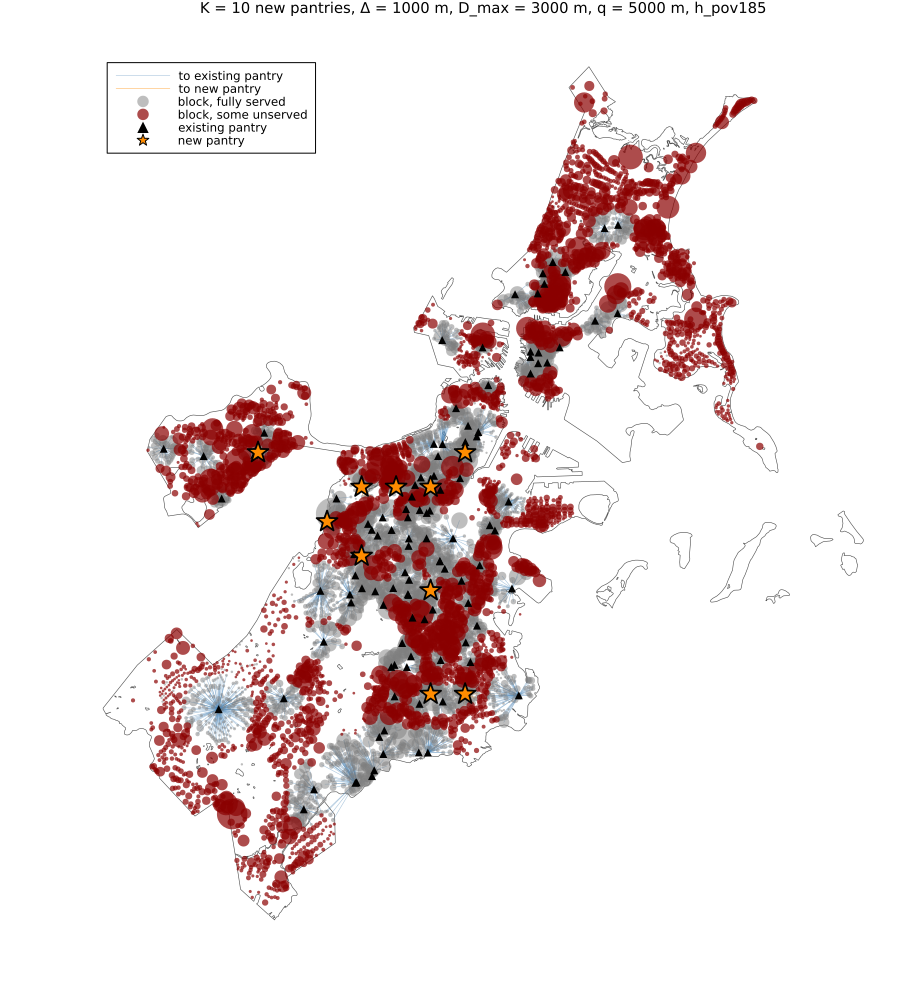

In [9]:
# Lines from each demand point to every site it uses, one series per site type (NaN breaks the line)
function flow_lines(sites)
    xs, ys = Float64[], Float64[]
    for i in I, j in A[i]
        if j in sites && w_val[i, j] > 0.5
            append!(xs, [blocks.x_i[i], site_x[j], NaN])
            append!(ys, [blocks.y_i[i], site_y[j], NaN])
        end
    end
    return xs, ys
end

ox = coalesce.(outline.X, NaN)
oy = coalesce.(outline.Y, NaN)
size_of(n) = 1 .+ 0.6 .* sqrt.(n)
short = block_results.unserved .> 0.5

p = plot(ox, oy; color = :gray30, lw = 0.6, label = "", aspect_ratio = :equal,
         axis = false, grid = false, size = (900, 1000), legend = :topleft,
         title = "K = $K new pantries, Δ = $(DELTA) m, D_max = $(D_MAX) m, q = $(Q) m, $(DEMAND)",
         titlefontsize = 10)
fx, fy = flow_lines(J_E);   plot!(p, fx, fy; color = :steelblue, alpha = 0.45, lw = 0.6, label = "to existing pantry")
fx, fy = flow_lines(built); plot!(p, fx, fy; color = :darkorange, alpha = 0.6, lw = 0.6, label = "to new pantry")
scatter!(p, block_results.x[.!short], block_results.y[.!short]; ms = size_of(block_results.in_need[.!short]),
         color = :gray50, alpha = 0.5, markerstrokewidth = 0, label = "block, fully served")
scatter!(p, block_results.x[short], block_results.y[short]; ms = size_of(block_results.in_need[short]),
         color = :darkred, alpha = 0.7, markerstrokewidth = 0, label = "block, some unserved")
scatter!(p, site_x[J_E], site_y[J_E]; marker = :utriangle, ms = 4, color = :black, label = "existing pantry")
scatter!(p, site_x[built], site_y[built]; marker = :star5, ms = 11, color = :darkorange,
         markerstrokecolor = :black, label = "new pantry")
savefig(p, joinpath("results", "map.png"))
p